# 02 — Prepare all-position 40-yard recordings

Prepare all recorded 40-yard attempts for the main position/time/player comparison. Retain single-recording players, separate attempts, and quality flags. There is no WR-only or NFL-participation filter.

This notebook checks timing and measurement consistency, computes observed signed-acceleration peaks with the revised direct polynomial method, and exports data for Notebook 03. It does not infer missing physical launch frames or confirm the official finish line. Physical units remain unverified; timing is referenced to recording start.

The earlier detailed diagnostics, superseded derivative/boundary checks, and WR-only exports are preserved in `archive/02_preparation_diagnostics.ipynb`. They are not dependencies of the main workflow. The existing WR/NFL pilot outputs remain unchanged.


## 1. Load all 40-yard attempts and position metadata

Use the existing local download; no Kaggle API login. Set `EXISTING_DATA_DIR` if the files are outside this project's data folder. Keep Combine position and NFL position distinct. Group comparisons by Combine position; exact official times are stored at published hundredth-second precision. A player's official 40 is not a verified time for each recorded attempt.


In [1]:
from pathlib import Path
import hashlib
import importlib
import json
import sys
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/"scripts/player_comparison.py").is_file()),None)

if ROOT is None:
    raise FileNotFoundError("Open the project folder or its notebooks folder")

OUTPUT=ROOT/"outputs/preparation_checks"
OUTPUT.mkdir(parents=True,exist_ok=True)

if str(ROOT/"scripts") not in sys.path:
    sys.path.insert(0,str(ROOT/"scripts"))

import player_comparison
import audit_data
importlib.reload(player_comparison)
importlib.reload(audit_data)

EXISTING_DATA_DIR=None  # Set your existing download folder if needed.

search_root=Path(EXISTING_DATA_DIR).expanduser() if EXISTING_DATA_DIR else ROOT/"data"
candidates=list(search_root.rglob("combine_tracking.csv"))

if not candidates and Path("/kaggle/input").is_dir():
    candidates=list(Path("/kaggle/input").rglob("combine_tracking.csv"))

if len(candidates)!=1:
    raise ValueError(f"Expected one combine_tracking.csv; found {len(candidates)}. Set EXISTING_DATA_DIR.")

DATA_DIR=candidates[0].parent

tracking=pd.read_csv(DATA_DIR/"combine_tracking.csv",dtype="string")

players=pd.read_csv(DATA_DIR/"players.csv",dtype="string")

results=pd.read_csv(DATA_DIR/"combine_results.csv",dtype="string")

GROUP_COLS=["draft_year","event_id","nfl_id","entity_type","drill_name","attempt"]

forties=tracking.loc[tracking["drill_name"].eq("FORTY_YARD_DASH")
                    & tracking["entity_type"].eq("PLAYER")].copy()
forties["time"]=pd.to_datetime(forties["time"],errors="coerce")

for col in ["x","y","s","a"]:
    forties[col]=pd.to_numeric(forties[col],errors="coerce").astype(float)
    forties.loc[~np.isfinite(forties[col]),col]=np.nan

if forties[GROUP_COLS].isna().any().any():
    raise ValueError("Missing attempt keys; review before defining player recordings")

attempt_ids=forties[GROUP_COLS].drop_duplicates()

roster=attempt_ids.groupby(["draft_year","nfl_id"],dropna=False).size().rename("recordings").reset_index()
roster=roster.merge(results[["draft_year","nfl_id","combine_position","forty","ten_yd_split",
                            "combine_height","combine_weight"]],
                    on=["draft_year","nfl_id"],how="left",validate="one_to_one",indicator=True)

if not roster["_merge"].eq("both").all():
    raise ValueError("A tracked player has no Combine results row")

roster=roster.drop(columns="_merge").merge(players[["nfl_id","display_name","nfl_position"]],
                                        on="nfl_id",how="left",validate="one_to_one")

if roster[["combine_position","display_name"]].isna().any().any():
    raise ValueError("Missing position or identity metadata")

roster["forty"]=pd.to_numeric(roster["forty"],errors="coerce")
roster["official_forty_hundredths"]=(roster["forty"]*100).round().astype("Int64")

all_frames=forties.merge(roster[["draft_year","nfl_id","display_name","nfl_position",
                                "combine_position","official_forty_hundredths"]],
                         on=["draft_year","nfl_id"],how="left",validate="many_to_one")

print("Players:",len(roster),"Recordings:",len(attempt_ids),"Frames:",len(all_frames))
display(roster.groupby("combine_position").agg(players=("nfl_id","size"),recordings=("recordings","sum")))
print("Players missing an official 40:",int(roster["official_forty_hundredths"].isna().sum()))

Players: 418 Recordings: 793 Frames: 41500


,players,recordings
combine_position,,
DB,102,195
DL,93,177
OL,95,179
TE,34,66
WR,94,176


Players missing an official 40: 0


## 2. Check timestamps, missing measurements, and recording coverage

Count invalid values and duplicate timestamps explicitly. Attempt summaries are descriptive recording summaries, not official dash durations. First observed speed is not proof of the physical start. Missing coordinates prevent spatial totals; missing speed prevents a supported acceleration estimate. No frame is silently removed or reconstructed.


In [2]:
coverage,quality=audit_data.tracking_diagnostics(
    all_frames,GROUP_COLS,"time",speed_col="s",acceleration_col="a",time_scale=1.0)

coverage=coverage.merge(roster[["draft_year","nfl_id","display_name","combine_position","nfl_position"]],
                         on=["draft_year","nfl_id"],how="left",validate="many_to_one")

coordinate_counts=all_frames.assign(invalid_coordinates=all_frames[["x","y"]].isna().any(axis=1))
coordinate_counts=coordinate_counts.groupby(GROUP_COLS,dropna=False)["invalid_coordinates"].sum().rename("invalid_coordinate_frames").reset_index()

coverage=coverage.merge(coordinate_counts,on=GROUP_COLS,how="left",validate="one_to_one")
coverage["launch_coverage"]="Unverified"
coverage["finish_coverage"]="Unverified"

display(pd.Series(quality,name="Value").to_frame())
display(coverage.groupby("combine_position").agg(
    recordings=("event_id","size"),median_duration_s=("observed_duration_s","median"),
    max_duration_s=("observed_duration_s","max"),duplicate_timestamp_rows=("duplicate_timestamp_rows","sum"),
    irregular_gap_count=("gaps_over_1_5x_median","sum"),invalid_coordinate_frames=("invalid_coordinate_frames","sum")))

print("Longest recordings — flagged for inspection, not automatically excluded:")
display(coverage.nlargest(5,"observed_duration_s")[["display_name","combine_position","attempt","observed_duration_s"]])


,Value
input_rows,41500
invalid_time_rows,0
missing_group_key_rows,0
excluded_rows,0
rows_in_duplicate_timestamps,0
start_coverage,UNVERIFIED: first observed frame is not necess...
finish_coverage,UNVERIFIED: confirm spatial coverage separately
speed_units,raw units; verify against data dictionary
s_invalid_rows,0
a_invalid_rows,0


,recordings,median_duration_s,max_duration_s,duplicate_timestamp_rows,irregular_gap_count,invalid_coordinate_frames
combine_position,,,,,,
DB,195,4.9,8.9,0,0,0
DL,177,5.2,5.9,0,0,0
OL,179,5.5,6.2,0,0,0
TE,66,5.0,5.6,0,0,0
WR,176,4.9,6.0,0,0,0


Longest recordings — flagged for inspection, not automatically excluded:


,display_name,combine_position,attempt,observed_duration_s
637,Jay Ward,DB,4,8.9
312,Dominick Puni,OL,1,6.2
348,Max Melton,DB,1,6.2
47,Torricelli Simpkins,OL,1,6.1
302,Trevor Keegan,OL,1,6.1


## 3. Check the supplied acceleration and compute signed observed peaks

Compare `a` with signed change in supplied speed. Nonnegative `a` during slowing is evidence not to interpret it as signed tangential acceleration; it does not by itself identify the vendor's precise calculation.

The measurement method used by Notebook 03 is a quadratic Savitzky–Golay direct first derivative of `s`, with 5-, 7-, and 9-frame sensitivity windows. Use only complete centered windows; do not use extrapolated edge derivatives. Retain invalid-attempt and boundary-peak statuses. A supported interior peak is an observed maximum, not proof the entire physical sprint peak was captured. Smoothing sensitivity and repeatability remain available in the main comparison and Notebook 03 summaries.


In [3]:
DECREASE_THRESHOLD=-0.5  # Exploratory raw-speed-units/second diagnostic.

definition_rows=[]

for key,frames in all_frames.groupby(GROUP_COLS,dropna=False,sort=False):
    row={**dict(zip(GROUP_COLS,key)),"combine_position":frames["combine_position"].iloc[0]}
    try:
        curve=player_comparison.attempt_curve(frames,7)
        frames=frames.sort_values("time")
        derivative=np.gradient(curve["speed"],curve["t"],edge_order=2)
        supplied_a=frames["a"].to_numpy(dtype=float)
        interior=(curve["t"]>=.2)&(curve["t"]<=curve["t"][-1]-.2)
        valid=interior&np.isfinite(supplied_a)
        falling=valid&(derivative<DECREASE_THRESHOLD)
        row.update(status="Checked",interior_frames=int(valid.sum()),
                   negative_supplied_a_frames=int((supplied_a[valid]<0).sum()),
                   falling_speed_frames=int(falling.sum()),
                   falling_speed_with_positive_a=int((supplied_a[falling]>0).sum()))
    
    except ValueError as exc:
        row.update(status="Review required",review_reason=str(exc))
    
    definition_rows.append(row)

acceleration_definition=pd.DataFrame(definition_rows)

display(acceleration_definition.groupby("combine_position")[["interior_frames","negative_supplied_a_frames",
    "falling_speed_frames","falling_speed_with_positive_a"]].sum())

all_peak_measurements=player_comparison.measure_all_attempts(all_frames,GROUP_COLS)

print("Supported measurement status for every attempt and sensitivity window:")
display(all_peak_measurements.groupby(["combine_position","window_frames","status"]).size().rename("recordings").to_frame())

print("Boundary flags for measured peaks:")
display(pd.crosstab([all_peak_measurements["combine_position"],all_peak_measurements["window_frames"]],
                    all_peak_measurements["peak_location"]))


,interior_frames,negative_supplied_a_frames,falling_speed_frames,falling_speed_with_positive_a
combine_position,,,,
DB,8946,0,29,29
DL,8678,0,78,78
OL,9302,0,76,76
TE,3125,0,17,17
WR,8135,0,30,30


Supported measurement status for every attempt and sensitivity window:


recordings
combine_position window_frames status              
DB               5             Measured         195
                 7             Measured         195
                 9             Measured         195
DL               5             Measured         177
                 7             Measured         177
                 9             Measured         177
OL               5             Measured         179
                 7             Measured         179
                 9             Measured         179
TE               5             Measured          66
                 7             Measured          66
                 9             Measured          66
WR               5             Measured         176
                 7             Measured         176
                 9             Measured         176

Boundary flags for measured peaks:


peak_location                   Interior  Start boundary
combine_position window_frames                          
DB               5                   194               1
                 7                   191               4
                 9                   186               9
DL               5                   175               2
                 7                   173               4
                 9                   164              13
OL               5                   177               2
                 7                   173               6
                 9                   154              25
TE               5                    64               2
                 7                    62               4
                 9                    61               5
WR               5                   175               1
                 7                   174               2
                 9                   171               5

## 4. Cross-check supplied speed against recorded position

For every attempt, compare adjacent-position distance divided by elapsed seconds with mean supplied speed over the same interval. A high correlation and similar numerical scale support internal consistency, but position and speed can share upstream processing. This is not independent film validation and does not establish physical units. Coordinate rounding and differentiation add noise. Keep failure statuses rather than forcing an estimate.


In [4]:
consistency_rows=[]

for key,frames in all_frames.groupby(GROUP_COLS,dropna=False,sort=False):
    frames=frames.sort_values("time")
    row={**dict(zip(GROUP_COLS,key)),"display_name":frames["display_name"].iloc[0],
         "combine_position":frames["combine_position"].iloc[0]}
    
    try:
        checked=player_comparison.attempt_curve(frames,7)
        x=frames["x"].to_numpy(dtype=float);y=frames["y"].to_numpy(dtype=float)
        
        if not np.isfinite(x).all() or not np.isfinite(y).all():
            raise ValueError("Invalid recorded coordinates")
        dt=np.diff(checked["t"])
        path=np.hypot(np.diff(x),np.diff(y))
        position_speed=path/dt
        supplied_mid=(checked["speed"][:-1]+checked["speed"][1:])/2
        ratio_valid=supplied_mid>2
        correlation=(np.corrcoef(position_speed,supplied_mid)[0,1]
                     
                     if np.std(position_speed)>0 and np.std(supplied_mid)>0 else np.nan)
        row.update(status="Checked",interval_speed_correlation=correlation,
                   position_path_coordinate_units=float(path.sum()),
                   integrated_supplied_speed_raw=float(np.sum(supplied_mid*dt)),
                   median_position_to_supplied_ratio_above_2_raw=(
                       float(np.median(position_speed[ratio_valid]/supplied_mid[ratio_valid]))
                       
                       if ratio_valid.any() else np.nan))
    except ValueError as exc:
        row.update(status="Review required",review_reason=str(exc))
    
    consistency_rows.append(row)

position_speed_checks=pd.DataFrame(consistency_rows)

display(position_speed_checks.groupby(["combine_position","status"]).agg(
    recordings=("event_id","size"),median_speed_correlation=("interval_speed_correlation","median"),
    median_position_to_supplied_ratio=("median_position_to_supplied_ratio_above_2_raw","median")))

,,recordings,median_speed_correlation,median_position_to_supplied_ratio
combine_position,status,,,
DB,Checked,195,0.998988,1.001574
DL,Checked,177,0.998863,1.001619
OL,Checked,179,0.998599,1.001252
TE,Checked,66,0.999066,1.001487
WR,Checked,176,0.999116,1.001556


## 5. One recording example: extra activity before the sprint

Jay Ward's attempt 4 contains movement and a pause before the main speed buildup. Plot its position and speed alongside his other recording to show why recording start is not physical launch. This example documents a review concern; it does not establish an automatic trimming rule. Detailed player investigations and earlier onset/threshold experiments remain in the archive. Change `REVIEW_PLAYER_ID` to inspect another player without changing the preparation cohort.


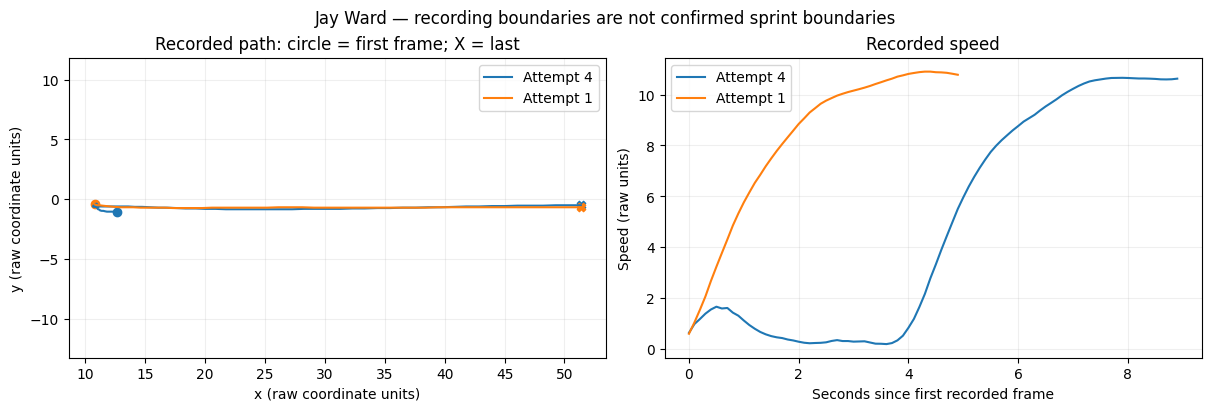

In [ ]:
REVIEW_PLAYER_ID= "55999"  # Jay Ward

review=all_frames.loc[all_frames["nfl_id"].eq(REVIEW_PLAYER_ID)]

if not review.empty:
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    
    for key,frames in review.groupby(GROUP_COLS,dropna=False,sort=False):
        frames=frames.sort_values("time")
        
        if frames["time"].isna().any():
            print("Review invalid timestamps before plotting",key);continue
        t=(frames["time"]-frames["time"].iloc[0]).dt.total_seconds()
        label=f"Attempt {frames['attempt'].iloc[0]}"
        line,=axes[0].plot(frames["x"],frames["y"],label=label)
        axes[0].scatter(frames["x"].iloc[0],frames["y"].iloc[0],color=line.get_color(),marker="o")
        axes[0].scatter(frames["x"].iloc[-1],frames["y"].iloc[-1],color=line.get_color(),marker="X")
        axes[1].plot(t,frames["s"],label=label)
    
    axes[0].set(title="Recorded path: circle = first frame; X = last",xlabel="x (raw coordinate units)",ylabel="y (raw coordinate units)")
    axes[0].set_aspect("equal",adjustable="datalim")
    axes[1].set(title="Recorded speed",xlabel="Seconds since first recorded frame",ylabel="Speed (raw units)")
    
    for ax in axes:ax.grid(alpha=.2);ax.legend()
    fig.suptitle(f"{review['display_name'].iloc[0]} — recording boundaries are not confirmed sprint boundaries")
    plt.show()

else:
    print("Review player not found; no recording has been excluded.")


## 6. Export all-position measurements and quality evidence

This is the only handoff required by the main Notebook 03. Preserve every recording, position metadata, observed peak estimates, and audit results in `outputs/prepared_all_positions/`. No automatic exclusion is based on an unusual duration, a discrepancy, or missing NFL opportunity. Unsupported measurements keep their status and are not reconstructed.

The three manually investigated discrepancy players remain flagged for review, without assigning a cause. A False flag means no such individual review was recorded; it is not a universal quality-pass designation. Physical units and physical launch/finish coverage remain explicit unresolved items.

The earlier WR-only handoff and NFL validation outputs are not regenerated here. Run the archived preparation notebook only if deliberately reproducing that earlier pilot.


In [6]:
ALL_PREPARED=ROOT/"outputs/prepared_all_positions"
ALL_PREPARED.mkdir(parents=True,exist_ok=True)

roster["discrepancy_review"]=roster["nfl_id"].isin(["57256","57152","57155"])
roster["review_note"]=np.where(roster["discrepancy_review"],
    "Retained: between-recording acceleration discrepancy reviewed; cause unresolved",
    "No individual discrepancy review recorded; not a quality-pass designation")

exports={"all_forty_frames.csv":all_frames,"all_player_roster.csv":roster,
         "all_observed_peaks.csv":all_peak_measurements,"recording_coverage.csv":coverage,
         "acceleration_definition_checks.csv":acceleration_definition,
         "position_speed_checks.csv":position_speed_checks}

manifest={"schema_version":1,"created_utc":datetime.now(timezone.utc).isoformat(),
    "group_columns":GROUP_COLS,"position_definition":"combine_position; nfl_position retained separately",
    "time_definition":"Seconds since first recorded frame; not confirmed physical launch",
    "peak_definition":"Direct Savitzky-Golay first derivative of s; quadratic fit; complete centered windows only",
    "units":"Raw supplied-speed units per second; physical units unverified",
    "quality_summary":quality,
    "limitations":["Physical units unverified","Launch/finish coverage unverified",
                   "Position and supplied speed are not independent validation",
                   "Official player-level 40 is not mapped to every attempt"],"files":{}}

for name,table in exports.items():
    target=ALL_PREPARED/name;table.to_csv(target,index=False)
    manifest["files"][name]={"rows":len(table),"sha256":hashlib.sha256(target.read_bytes()).hexdigest()}

(ALL_PREPARED/"manifest.json").write_text(json.dumps(manifest,indent=2)+"\n")
(OUTPUT/"quality_summary.json").write_text(json.dumps(quality,indent=2)+"\n")

display(pd.DataFrame([{"file":name,"rows":info["rows"]} for name,info in manifest["files"].items()]))
print("All-position handoff saved:",ALL_PREPARED)
print("Next: run Notebook 03 from the top. The detailed archive is not required.")


,file,rows
0,all_forty_frames.csv,41500
1,all_player_roster.csv,418
2,all_observed_peaks.csv,2379
3,recording_coverage.csv,793
4,acceleration_definition_checks.csv,793
5,position_speed_checks.csv,793


All-position handoff saved: /Users/hunterclark/Documents/New project/nfl-big-data-bowl-2027/outputs/prepared_all_positions
Next: run Notebook 03 from the top. The detailed archive is not required.
